# 3. Stratégie contre le déséquilibre et réglage

Comparaison, en validation, des stratégies appliquées au seul jeu d'entraînement : aucune correction, pondération des classes, sous-échantillonnage des transactions normales à plusieurs rapports, SMOTE.
Les résultats proviennent de `src/lancer_desequilibre.py` et `src/lancer_reglage.py`.

In [1]:
import sys
from pathlib import Path

RACINE = Path.cwd().resolve().parent
if str(RACINE) not in sys.path:
    sys.path.insert(0, str(RACINE))

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", message="IProgress not found")
pd.options.display.float_format = "{:,.4f}".format
pd.options.display.max_columns = 30
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

BLEU = "#2a78d6"
ORANGE = "#eb6834"
VERT = "#1baf7a"
JAUNE = "#eda100"
ROSE = "#e87ba4"

In [2]:
import json
from src import application

comparaison = pd.read_csv(RACINE / "resultats" / "comparaison_desequilibre.csv")
comparaison["strategie"] = comparaison["strategie"].map(lambda s: application.LIBELLES_STRATEGIES.get(s, s))
comparaison

,modele,strategie,pr_auc,roc_auc,precision_a_k,rappel_a_k,cout,pr_auc_ecart_type,tirages
0,logistique,Aucune,0.4516,0.9151,0.3746,0.5508,"136,198.1900",0.0000,1
1,logistique,Sous-échantillonnage 1:20,0.3400,0.9293,0.3506,0.5155,"142,319.7100",0.0082,3
2,logistique,Sous-échantillonnage 1:10,0.2870,0.9323,0.3416,0.5022,"142,122.4267",0.0043,3
3,logistique,SMOTE 1:10,0.2831,0.9324,0.3404,0.5004,"145,702.4467",0.0015,3
4,logistique,Sous-échantillonnage 1:5,0.2394,0.9347,0.3351,0.4927,"142,533.8533",0.0044,3
5,logistique,Sous-échantillonnage 1:1,0.1811,0.9372,0.3048,0.4482,"161,552.7733",0.0084,3
6,logistique,Pondération des classes,0.1803,0.9375,0.3020,0.4440,"160,913.0600",0.0000,1
7,xgboost,SMOTE 1:10,0.9181,0.9986,0.6293,0.9253,"33,717.8367",0.0011,3
8,xgboost,Sous-échantillonnage 1:20,0.9170,0.9985,0.6297,0.9258,"29,335.2500",0.0003,3
9,xgboost,Sous-échantillonnage 1:10,0.9143,0.9985,0.6281,0.9235,"29,021.0067",0.0019,3


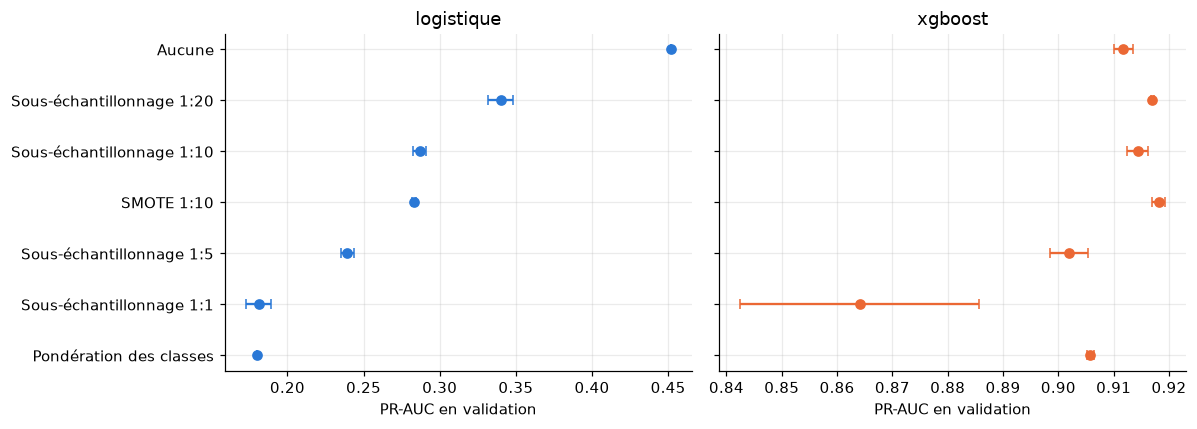

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, modele, couleur in zip(axes, ["logistique", "xgboost"], [BLEU, ORANGE]):
    sous = comparaison[comparaison["modele"] == modele].sort_values("pr_auc")
    ax.errorbar(sous["pr_auc"], sous["strategie"], xerr=sous["pr_auc_ecart_type"].fillna(0), fmt="o", color=couleur, capsize=3)
    ax.set_title(modele)
    ax.set_xlabel("PR-AUC en validation")
fig.tight_layout()

In [4]:
comparaison.sort_values("cout").groupby("modele").head(3)[["modele", "strategie", "pr_auc", "precision_a_k", "rappel_a_k", "cout"]]

,modele,strategie,pr_auc,precision_a_k,rappel_a_k,cout
12,xgboost,Sous-échantillonnage 1:5,0.9019,0.6267,0.9214,"28,907.1433"
9,xgboost,Sous-échantillonnage 1:10,0.9143,0.6281,0.9235,"29,021.0067"
8,xgboost,Sous-échantillonnage 1:20,0.9170,0.6297,0.9258,"29,335.2500"
0,logistique,Aucune,0.4516,0.3746,0.5508,"136,198.1900"
2,logistique,Sous-échantillonnage 1:10,0.2870,0.3416,0.5022,"142,122.4267"
1,logistique,Sous-échantillonnage 1:20,0.3400,0.3506,0.5155,"142,319.7100"


## Correction des probabilités

Si l'on ne conserve qu'une proportion β des transactions normales, la probabilité ps estimée sur l'échantillon rééquilibré est corrigée par

    p = β · ps / (β · ps − ps + 1)

où β est la part des transactions normales conservées. Sans cette correction, les probabilités affichées dans l'application seraient surestimées.

In [5]:
from src import desequilibre

ps = np.array([0.5, 0.9, 0.99])
pd.DataFrame({beta: desequilibre.corriger_probabilites(ps, beta) for beta in (0.2, 0.05, 0.01)}, index=ps)

,0.2000,0.0500,0.0100
0.5000,0.1667,0.0476,0.0099
0.9000,0.6429,0.3103,0.0826
0.9900,0.9519,0.8319,0.4975


## Réglage des hyperparamètres (validation croisée chronologique dans l'entraînement)

In [6]:
xgb = pd.read_csv(RACINE / "resultats" / "reglage_xgboost.csv")
cols = ["n_estimators", "max_depth", "learning_rate", "subsample", "colsample_bytree", "min_child_weight", "pr_auc_moyenne", "pr_auc_ecart_type", "duree", "reference"]
xgb.sort_values("pr_auc_moyenne", ascending=False)[cols].head(8)

,n_estimators,max_depth,learning_rate,subsample,colsample_bytree,min_child_weight,pr_auc_moyenne,pr_auc_ecart_type,duree,reference
0,300,6,0.1000,0.8000,0.8000,1,0.9086,0.0357,20.1968,True
1,394,8,0.0633,0.9610,0.6083,7,0.9080,0.0362,31.5928,False
2,359,6,0.1478,0.9667,0.7071,5,0.9074,0.0348,17.8326,False
3,445,6,0.0774,0.8790,0.8895,4,0.9071,0.0343,16.1859,False
4,219,7,0.1075,0.8278,0.8754,3,0.9071,0.0359,11.2485,False
5,576,8,0.0620,0.9953,0.6052,10,0.9058,0.0370,44.6035,False
6,484,7,0.0435,0.6978,0.5510,5,0.9053,0.0356,29.7662,False
7,260,8,0.0533,0.8901,0.7059,6,0.9050,0.0339,13.4543,False


In [7]:
reference = xgb.loc[xgb["reference"]].iloc[0]
meilleure = xgb["pr_auc_moyenne"].max()
{"reference": reference["pr_auc_moyenne"], "meilleure": meilleure, "gain": meilleure - reference["pr_auc_moyenne"]}

{'reference': np.float64(0.9086217351513496),
 'meilleure': np.float64(0.9086217351513496),
 'gain': np.float64(0.0)}

In [8]:
logistique = pd.read_csv(RACINE / "resultats" / "reglage_logistique.csv")
logistique

,C,reference,pr_auc_moyenne,pr_auc_ecart_type,duree,pr_auc_pli_1,pr_auc_pli_2,pr_auc_pli_3
0,100.0000,False,0.4500,0.0526,8.4231,0.3902,0.4703,0.4894
1,10.0000,False,0.4499,0.0526,10.1477,0.3902,0.4702,0.4894
2,1.0000,False,0.4495,0.0525,10.7084,0.3900,0.4693,0.4892
3,0.1000,False,0.4449,0.0502,9.9864,0.3879,0.4644,0.4824
4,0.0100,False,0.4281,0.0509,6.0873,0.3714,0.4430,0.4699
5,0.0010,False,0.3274,0.0563,5.3915,0.2692,0.3312,0.3816


In [9]:
with open(RACINE / "resultats" / "meilleurs_parametres.json", encoding="utf-8") as fichier:
    retenus = json.load(fichier)
retenus

{'xgboost': {'n_estimators': 300,
  'max_depth': 6,
  'learning_rate': 0.1,
  'subsample': 0.8,
  'colsample_bytree': 0.8,
  'min_child_weight': 1,
  'tree_method': 'hist'},
 'logistique': {'C': 1.0}}

## Décision

La stratégie et les paramètres retenus sont ceux que la règle de parcimonie fixée avant les essais désigne : on ne quitte la configuration par défaut que si le gain de PR-AUC dépasse 0,001.